# Bayesian Probability:

[Link to GitHub Repository](https://github.com/L-nsamba/group-1-formative-3-probability-bayes-gradient-descent.git)

## 1. Data handling

### Dataset setup

Avoids repeated upload into colab filesysytem

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

dataset_path = Path("IMDB Dataset.csv")
archive_path = Path("imdb-dataset.zip")
dataset_url = "https://www.kaggle.com/api/v1/datasets/download/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"

if not dataset_path.is_file():
    print("Downloading the IMDB reviews dataset...")
    urlretrieve(dataset_url, archive_path)
    with ZipFile(archive_path) as archive:
        if "IMDB Dataset.csv" not in archive.namelist():
            raise FileNotFoundError("The downloaded archive does not contain IMDB Dataset.csv")
        archive.extract("IMDB Dataset.csv", path=".")

if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {dataset_path.resolve()}")
print(f"Successfully prepared {dataset_path}!")

Successfully prepared IMDB Dataset.csv!


## Format dataset
 . We strip punctuations and paragraph breaks

 . Only count one instance of a word per review

In [9]:
import csv

reviews = []

with open("IMDB Dataset.csv", encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        text = row["review"].lower()
        text = text.replace("<br />", " ")
        # take out punctuation so "good!" counts as "good"
        for ch in ".,!?;:\"()-/*":
            text = text.replace(ch, " ")
        words = set(text.split())  # store in a set so each word counts only once per review
        reviews.append((words, row["sentiment"]))

print(f"Successfully loaded {len(reviews)} total reviews!")

Successfully loaded 50000 total reviews!


## 3. Keyword selection
4 Keywords that indicate positive sentiment: "favorite", "excellent", "wonderful", "masterpiece"

4 Keywords that indicate negative sentiment: "boring", "horrible", "worst", "sucks"

## 4. Choice of conditional probability

For every selected keyword, we calculate `P(Negative | keyword)`.

In [10]:
negative_words = ["horrible", "boring", "worst", "sucks"]

## 5. Define useful variables

`total` is the number of reviews, and `total_negative_reviews` is the number labeled negative.

In [11]:
total = len(reviews)
total_negative_reviews = 0
for words, sentiment in reviews:
    if sentiment == "negative":
        total_negative_reviews = total_negative_reviews + 1

print("total reviews:", total)
print("negative reviews:", total_negative_reviews)

total reviews: 50000
negative reviews: 25000


## 6. Bayes' theorem implementation

The helper below applies `P(Negative | keyword) = P(keyword | Negative) * P(Negative) / P(keyword)`.

In [12]:
def bayes(prior, likelihood, evidence):
    return likelihood * prior / evidence

## 7. Calculate keyword probabilities

In [13]:
def negative_probability_for_keyword(word):
    with_word = 0        # reviews that have the word
    neg_with_word = 0    # negative reviews that have the word

    for words, sentiment in reviews:
        if word in words:
            with_word = with_word + 1
            if sentiment == "negative":
                neg_with_word = neg_with_word + 1

    if with_word == 0:
        return None

    prior = total_negative_reviews / total                 # P(Negative)
    likelihood = neg_with_word / total_negative_reviews    # P(word | Negative)
    marginal = with_word / total                           # P(word)
    posterior = bayes(prior, likelihood, marginal)         # P (Negative|word)
    check = neg_with_word / with_word                      # direct check

    return {
        "word": word,
        "prior": prior,
        "likelihood": likelihood,
        "marginal": marginal,
        "posterior": posterior,
        "check": check,
        "total_appearances": with_word,
        "negative_appearances": neg_with_word
    }

## 8. Computation and presentation (table)

In [15]:
results = []

print("Bayesian probability results for negative sentiment:")
print("| keyword | prior | likelihood | marginal | posterior  | direct check |")
print("|---------|-------|------------|----------|------------|--------------|")

for word in negative_words:
    result = negative_probability_for_keyword(word)

    if result is None:
        print(f"| {word} | word not found | | | | |")
        continue

    results.append(result)
    print(
        f"| {word} | {result['prior']:.4f} "
        f"| {result['likelihood']:.4f} "
        f"| {result['marginal']:.4f} "
        f"| {result['posterior']:.4f} "
        f"| {result['check']:.4f} |"
    )

Bayesian probability results for negative sentiment:
| keyword | prior | likelihood | marginal | posterior  | direct check |
|---------|-------|------------|----------|------------|--------------|
| horrible | 0.5000 | 0.0708 | 0.0419 | 0.8449 | 0.8449 |
| boring | 0.5000 | 0.0983 | 0.0610 | 0.8064 | 0.8064 |
| worst | 0.5000 | 0.1608 | 0.0886 | 0.9076 | 0.9076 |
| sucks | 0.5000 | 0.0190 | 0.0108 | 0.8764 | 0.8764 |


## 9. Visualization of Negative-Keyword Results

These charts show how each negative keyword updates the prior probability of a review being negative.

The second chart compares the likelihood P(keyword | Negative) with the posterior P(Negative | keyword); these are different probabilities.

This visualization uses Matplotlib; if it is not installed in your notebook environment, run `python -m pip install matplotlib`.

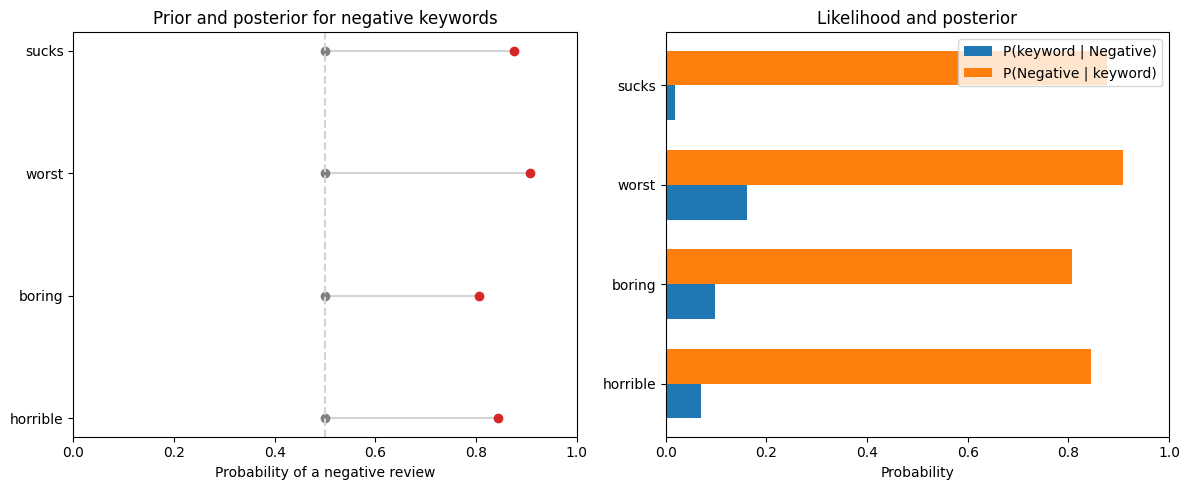

In [17]:
import matplotlib.pyplot as plt

positions = list(range(len(results)))
keywords = [result["word"] for result in results]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Prior-to-posterior update for each negative keyword
for index, result in enumerate(results):
    axes[0].plot(
        [result["prior"], result["posterior"]],
        [index, index],
        color="lightgray",
        zorder=1,
    )
    axes[0].scatter(result["prior"], index, color="gray", zorder=2)
    axes[0].scatter(result["posterior"], index, color="tab:red", zorder=2)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(keywords)
axes[0].set_xlim(0, 1)
axes[0].axvline(0.5, linestyle="--", color="lightgray")
axes[0].set_xlabel("Probability of a negative review")
axes[0].set_title("Prior and posterior for negative keywords")

# Compare likelihood with posterior
bar_height = 0.35

axes[1].barh(
    [index - bar_height / 2 for index in positions],
    [result["likelihood"] for result in results],
    height=bar_height,
    label="P(keyword | Negative)",
)
axes[1].barh(
    [index + bar_height / 2 for index in positions],
    [result["posterior"] for result in results],
    height=bar_height,
    label="P(Negative | keyword)",
)

axes[1].set_yticks(positions)
axes[1].set_yticklabels(keywords)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Probability")
axes[1].set_title("Likelihood and posterior")
axes[1].legend()

fig.tight_layout()
plt.show()

## 10. Interpretation and limitations

- `prior` is the share of all reviews labeled negative.
- `likelihood` is the share of negative reviews containing the keyword, while `marginal` is the share of all reviews containing it.
- `posterior` is the probability of a negative label given that the review contains the keyword. The direct check computes the same quantity from review counts and helps verify the Bayes calculation.
- A keyword is only a simple signal, not a full sentiment model. Negation, sarcasm, and context can make even positive-associated words appear in negative reviews.
- Results describe this dataset and these selected keywords. Exact matching misses related word forms, and the preprocessing retains apostrophes.